In [2]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

from mpl_toolkits.basemap import Basemap
import networkx as nx

In [4]:
%run Data_processing.py

In [8]:
df_interactions = pd.read_excel('../../../Data/Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions')

In [122]:
df_interactions

,Source,Target,Response,Strength,min,max
0,GIS,AMOC,Destabilising,Strong,0.1,10.0
1,WAIS,AMOC,Unclear,"Weak, Moderate",-3.0,3.0
2,AMOC,GIS,Stabilising,Strong,-10.0,-0.1
3,AMOC,WAIS,Destabilising,Unclear,0.1,1.5
4,GIS,WAIS,Destabilising,Moderate,0.1,5.0
5,WAIS,GIS,Destabilising,Weak,0.1,2.0
6,ASI,AMOC,Destabilising,"Weak, Moderate",0.1,3.0
7,AMOC,ASI,Stabilising,"Weak, Moderate",-3.0,-0.1
8,ASI,GIS,Destabilising,Weak,0.1,2.0
9,ASI,PERM,Destabilising,Weak,0.1,2.0


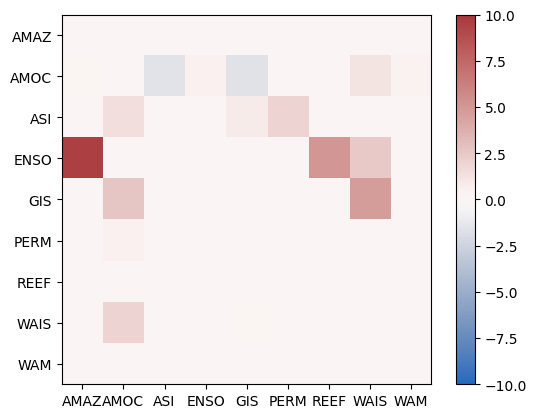

In [5]:
fig,ax=plt.subplots()
im=ax.imshow(A[100],vmin=-10,vmax=10,cmap='vlag')
ax.set_xticks(range(A[0].shape[0]), df_TEs.index.values)
ax.set_yticks(range(A[0].shape[0]), df_TEs.index.values)
plt.colorbar(im)

In [103]:
G = nx.from_pandas_edgelist(df_interactions,source='Source',target='Target',edge_attr=['min', 'max'],create_using=nx.DiGraph)
m = Basemap(projection='kav7',lon_0=-30,resolution='c',)
            # llcrnrlat=-80,urcrnrlat=80,llcrnrlon=-180,urcrnrlon=180,lat_ts=20,);
pos_lonlat = {'GIS':[-43,75], 'AMOC':[-30,40],'ENSO':[-115,-8.8],
              'WAIS':[-90,-75],'ASI':[0,68],'PERM':[70,60],
              'WAM':[0,15],'REEF':[-80,12],'AMAZ':[-62.2,-3.5]}
pos_xy ={k:m(v[0],v[1]) for k,v in pos_lonlat.items()}
T_lim_dic = df_TEs['Threshold (°C) – Est.'].to_dict()

In [110]:
elist = [(e[0],e[1],0) for e in G.edges]
earc_dic = {e:0 for e in G.edges}
earc_dic[('GIS','AMOC')]=0.2
earc_dic[('AMOC','GIS')]=0.2
earc_dic[('AMOC','WAIS')]=-0.5
earc_dic[('AMOC','ENSO')]=0.3
earc_dic[('WAIS','AMOC')]=0.3
earc_dic[('ASI','AMOC')]=0.15
earc_dic[('AMOC','ASI')]=0.15
earc_dic[('ASI','GIS')]=0.1
earc_dic[('PERM','AMOC')]=-0.15
earc_dic[('ASI','PERM')]=-0.1
earc_dic[('PERM','ASI')]=-0.1
earc_dic[('WAIS','GIS')]=-0.9
earc_dic[('GIS','WAIS')]=1.4

For automatic curved edges check out netgraph: \
https://stackoverflow.com/questions/52588453/drawing-curved-edges-with-networkx-in-python \
https://github.com/paulbrodersen/netgraph/tree/master

## designing the network subpanel

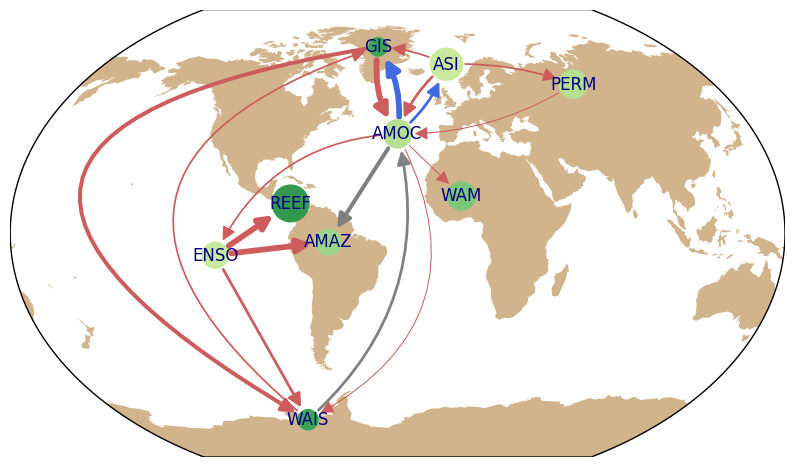

In [123]:
fig,ax=plt.subplots(figsize=(10,8))

node_size=[1600/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes]
m.fillcontinents(color='tan',lake_color='tan',ax=ax);
nx.draw_networkx(G,ax=ax,pos=pos_xy,
                 node_size=node_size,with_labels=True,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=-1.5,vmax=7,cmap='YlGn_r',
                 font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'indianred'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'royalblue'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.8,
                           node_size=[n+200 for n in node_size],
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])),
                           arrowsize=20
                          );

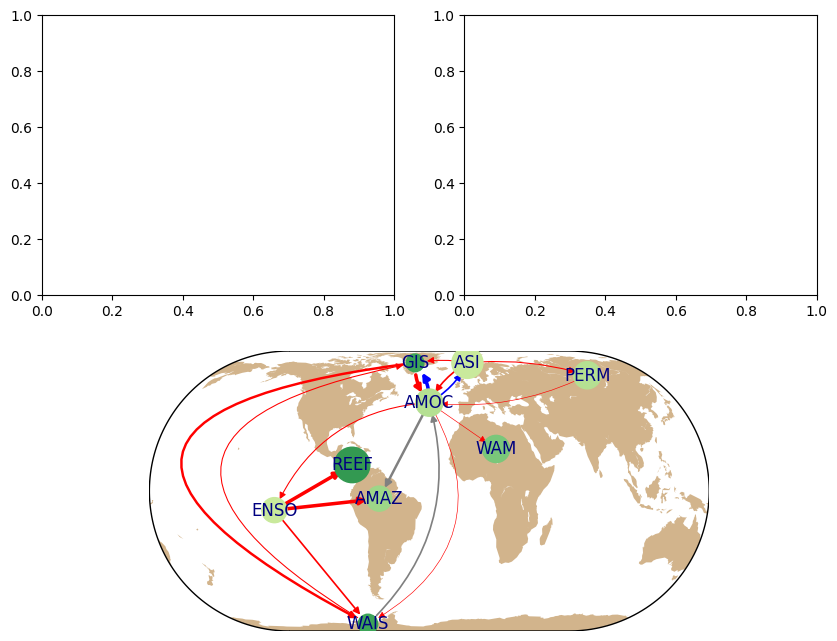

In [23]:
fig = plt.figure(figsize=(10,8))
ax1= fig.add_subplot(2,2,1)
ax2= fig.add_subplot(2,2,2)
ax3= fig.add_subplot(2,1,2)

m.fillcontinents(color='tan',lake_color='white',ax=ax3);
nx.draw_networkx(G,ax=ax3,pos=pos_xy,
                 node_size=[1500/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes],with_labels=True,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=-1.5,vmax=7,cmap='YlGn_r',
                 font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'r'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'b'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax3,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.1,
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])));
# m.drawcoastlines(ax=ax3)
# m.drawlsmask()

# Testing netgraph for visualisation

In [9]:
from netgraph import Graph

In [40]:
print(m(0,0))
print(m(-150,0))
print(m(210,0))

(19719303.91295753, 8451130.2484144)
(5634086.832266869, 8451130.2484144)
(5634086.832266871, 8451130.2484144)


TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'

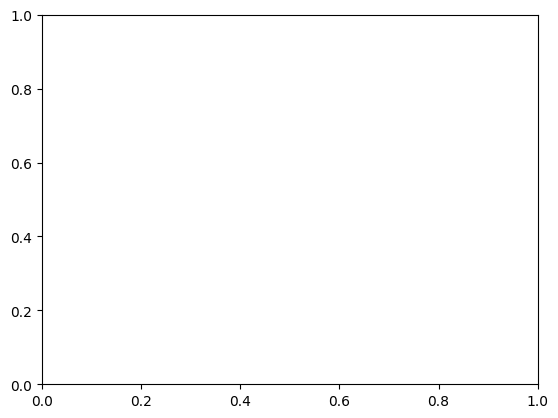

In [43]:
fig,ax=plt.subplots()
xmax = max([v[0] for k,v in pos_xy.items()])
ymax = max([v[1] for k,v in pos_xy.items()])
Graph(G, 
      node_layout={k:(v[0]/xmax,v[1]/ymax) for k,v in pos_xy.items()},
      ax=ax,edge_layout='curved')

In [20]:
print({k:(v[0]/360,v[1]/360) for k,v in pos_lonlat.items()})

{'GIS': (-0.11944444444444445, 0.19444444444444445), 'AMOC': (-0.08333333333333333, 0.11944444444444445), 'ENSO': (-0.3611111111111111, -0.024444444444444446), 'WAIS': (-0.25, -0.20833333333333334), 'ASI': (0.013888888888888888, 0.19444444444444445), 'PERM': (0.2777777777777778, 0.16666666666666666), 'WAM': (0.03888888888888889, 0.05416666666666667), 'REEF': (-0.2222222222222222, 0.03333333333333333), 'AMAZ': (-0.17277777777777778, -0.009722222222222222)}
